# Preprocessing of Hourly Data

## Libraries

In [126]:
import pandas as pd
import os
from utils import read_files
from utils import float_to_int
import matplotlib.pyplot as plt
import missingno as msno
import seaborn as sns

## Traffic Data

### Read and Tidy Data

In [127]:
# this folder is not on GitHub, because it's too large
path = "data/traffic_h1/"

files_traffic = os.listdir(path)

for i in range(len(files_traffic)):
    files_traffic[i] = os.path.join(path, files_traffic[i])

df_traffic_raw = read_files(file_paths=files_traffic, drop_columns=["MSID", "MSName", "ZSID", "Achse", "HNr", "Hoehe", "EKoord", "NKoord", "Knummer", "Kname", "AnzDetektoren", "D1ID", "D2ID", "D3ID", "D4ID", "LieferDat", "AnzFahrzeugeStatus"], date_column="MessungDatZeit", UTC=False)

Create a map for the stations, that the stations of the traffic data can be merged with the stations of the pollutant and meteo data.

In [128]:
station_map = {
    "Rosengartenstrasse (Nordstrasse)": "Zch_Rosengartenstrasse",
    "Stampfenbachstrasse (Wasserwerkstrasse)": "Zch_Stampfenbachstrasse",
    "Schimmelstrasse (Werdstrasse)": "Zch_Schimmelstrasse"
}

In [129]:
df_traffic_raw = df_traffic_raw[df_traffic_raw["ZSName"].isin(station_map)]

In [130]:
df_traffic_raw["Location"] = df_traffic_raw["ZSName"].map(station_map)

In [131]:
# select the necessary columns only
df_traffic_raw = df_traffic_raw.loc[:, ["Richtung", "Year", "Datetime", "Location", "AnzFahrzeuge"]]

In [132]:
df_traffic_raw.head()

,Richtung,Year,Datetime,Location,AnzFahrzeuge
614880,Bucheggplatz,2012,2011-12-31 23:00:00+00:00,Zch_Rosengartenstrasse,561.0
614881,Bucheggplatz,2012,2012-01-01 00:00:00+00:00,Zch_Rosengartenstrasse,1223.0
614882,Bucheggplatz,2012,2012-01-01 01:00:00+00:00,Zch_Rosengartenstrasse,989.0
614883,Bucheggplatz,2012,2012-01-01 02:00:00+00:00,Zch_Rosengartenstrasse,826.0
614884,Bucheggplatz,2012,2012-01-01 03:00:00+00:00,Zch_Rosengartenstrasse,823.0


### Check Datetime Column

Here we check whether the function "read_files" has handled the time zone conversions correctly.

In [133]:
# Time is checked in UTC. Therefore no problem with daylight saving time.

df_traffic_raw["Date"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.date
df_traffic_raw["Hour"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.hour

hour_counts = (
    df_traffic_raw
    .groupby(["Location", "Date"])
    .size()
    .rename("n_hours")
    .reset_index()
)

missing_hours = hour_counts[hour_counts['n_hours'] != 48]
missing_hours

,Location,Date,n_hours
0,Zch_Rosengartenstrasse,2011-12-31,2
5114,Zch_Rosengartenstrasse,2025-12-31,46
5115,Zch_Schimmelstrasse,2011-12-31,2
10229,Zch_Schimmelstrasse,2025-12-31,46
10230,Zch_Stampfenbachstrasse,2011-12-31,2
15344,Zch_Stampfenbachstrasse,2025-12-31,46


As we converted the CET/CEST datetime column to UTC, there are two data points in 2011 and 46 only in 2025. This is correct. We check for 48 instead of 24 because for each day and hour, the traffic is measured in two directions. Therefore, each station and datetime consists of two data points. We will handle this later in the notebook.

### Separate Datetime Column

For further analysis, separate the date time column.

In [134]:
df_traffic_raw["Date"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.date
df_traffic_raw["Time"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.time
df_traffic_raw["Month"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.month_name().str[:3]
df_traffic_raw["Weekday"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.day_name().str[:3]

In [135]:
df_traffic_raw["YearMonth"] = pd.to_datetime(df_traffic_raw["Year"].astype(str)
                                             + "-"
                                             + df_traffic_raw["Month"].astype(str))

C:\Users\selin\AppData\Local\Temp\ipykernel_36208\488087258.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_traffic_raw["YearMonth"] = pd.to_datetime(df_traffic_raw["Year"].astype(str)


### Check Zero Values

Now we check the hourly traffic data for zero values.

In [136]:
(df_traffic_raw
    .assign(is_na=df_traffic_raw["AnzFahrzeuge"].isna())
    .groupby(["Year", "Location"], as_index=False)
    .agg(n_missing_AnzFhz=("is_na", "sum"),
        count_Datetime=("Datetime", "count"),
        count_AnzFhz=("AnzFahrzeuge", "count"))
    .assign(
        missing_AnzFhz_perc=lambda d: round((d.count_Datetime - (d.count_Datetime-d.n_missing_AnzFhz))/d.count_Datetime*100, 2))

)

,Year,Location,n_missing_AnzFhz,count_Datetime,count_AnzFhz,missing_AnzFhz_perc
0,2012,Zch_Rosengartenstrasse,2671,17568,14897,15.20
1,2012,Zch_Schimmelstrasse,66,17568,17502,0.38
2,2012,Zch_Stampfenbachstrasse,72,17568,17496,0.41
3,2013,Zch_Rosengartenstrasse,5123,17520,12397,29.24
4,2013,Zch_Schimmelstrasse,16,17520,17504,0.09
5,2013,Zch_Stampfenbachstrasse,16,17520,17504,0.09
6,2014,Zch_Rosengartenstrasse,17520,17520,0,100.00
7,2014,Zch_Schimmelstrasse,14,17520,17506,0.08
8,2014,Zch_Stampfenbachstrasse,606,17520,16914,3.46
9,2015,Zch_Rosengartenstrasse,11767,17520,5753,67.16


There are some locations which miss a high number of traffic data. Problematic locations and years are:
- Rosengartenstrasse: 2012 - 2015
- Stampfenbachstrasse: 2016 and 2017

In [137]:
df_plot = (df_traffic_raw
.query("Location in ['Zch_Rosengartenstrasse', 'Zch_Stampfenbachstrasse']")
.query("Year in [2012, 2013, 2014, 2015, 2016, 2017]")
.groupby(["YearMonth", "Location"], as_index=False)
.agg(
        count_Datetime=("Datetime", "count"),
        count_AnzFhz=("AnzFahrzeuge", "count"))
.assign(
        count_missing_AnzFhz_perc=lambda d: round((d.count_Datetime - d.count_AnzFhz)/d.count_Datetime*100, 2)))

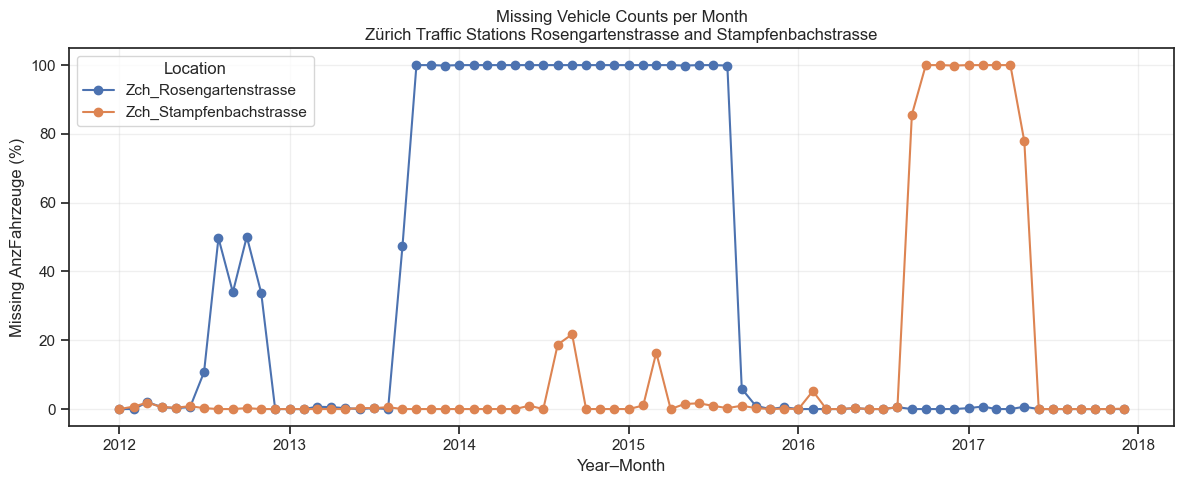

In [138]:
plt.figure(figsize=(12, 5))

for location, g in df_plot.groupby("Location"):
    plt.plot(
        g["YearMonth"],
        g["count_missing_AnzFhz_perc"],
        marker="o",
        label=location
    )

plt.ylabel("Missing AnzFahrzeuge (%)")
plt.xlabel("Year–Month")
plt.title("Missing Vehicle Counts per Month\nZürich Traffic Stations Rosengartenstrasse and Stampfenbachstrasse")

plt.legend(title="Location")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

We remove all NaNs and exclude years before 2018.

In [139]:
years = range(2018, 2026)

df_traffic_raw = df_traffic_raw[df_traffic_raw["Year"].isin(years)]

In [140]:
df_traffic = df_traffic_raw.dropna()

In [141]:
print("df_traffic incl. NaNs shape:", df_traffic_raw.shape)
print("df_traffic excl. NaNs shape:", df_traffic.shape)

df_traffic incl. NaNs shape: (420768, 11)
df_traffic excl. NaNs shape: (417976, 11)


### Check Number of Data Points

For each location and datetime, there are two values for number of vehicles, because the sensor measures in both directions. To be sure, we check whether there are locations with more or less than two data points per datetime.

In [142]:
direction_counts = (
    df_traffic
    .groupby(["Location", "Datetime"])
    .size()
    .rename("n_directions")
    .reset_index()
)

missing_direction = direction_counts[direction_counts['n_directions'] != 2]
missing_direction

,Location,Datetime,n_directions
4719,Zch_Rosengartenstrasse,2018-07-16 17:00:00+00:00,1
4720,Zch_Rosengartenstrasse,2018-07-16 18:00:00+00:00,1
4721,Zch_Rosengartenstrasse,2018-07-16 19:00:00+00:00,1
4722,Zch_Rosengartenstrasse,2018-07-16 20:00:00+00:00,1
4723,Zch_Rosengartenstrasse,2018-07-16 21:00:00+00:00,1
...,...,...,...
161977,Zch_Stampfenbachstrasse,2020-07-22 09:00:00+00:00,1
161978,Zch_Stampfenbachstrasse,2020-07-22 10:00:00+00:00,1
161979,Zch_Stampfenbachstrasse,2020-07-22 11:00:00+00:00,1
161980,Zch_Stampfenbachstrasse,2020-07-22 12:00:00+00:00,1


As there are nearly 5000 entries which miss the measurement of one lane / one direction, we rather calculate the average instead of the sum, so that we can keep these 4966 data points anyway.

In [143]:
df_traffic = (df_traffic
              .groupby(["Year", "Location", "Datetime", "Date", "Time", "Month", "Weekday", "YearMonth"], as_index=False)
              .agg(meanVehicles=("AnzFahrzeuge", "mean")))

In [144]:
print(df_traffic.shape)

(209484, 9)


In [145]:
df_traffic.head()

,Year,Location,Datetime,Date,Time,Month,Weekday,YearMonth,meanVehicles
0,2018,Zch_Rosengartenstrasse,2017-12-31 23:00:00+00:00,2017-12-31,23:00:00,Dec,Sun,2018-12-01,538.5
1,2018,Zch_Rosengartenstrasse,2018-01-01 00:00:00+00:00,2018-01-01,00:00:00,Jan,Mon,2018-01-01,1029.0
2,2018,Zch_Rosengartenstrasse,2018-01-01 01:00:00+00:00,2018-01-01,01:00:00,Jan,Mon,2018-01-01,791.5
3,2018,Zch_Rosengartenstrasse,2018-01-01 02:00:00+00:00,2018-01-01,02:00:00,Jan,Mon,2018-01-01,587.0
4,2018,Zch_Rosengartenstrasse,2018-01-01 03:00:00+00:00,2018-01-01,03:00:00,Jan,Mon,2018-01-01,505.0


In [146]:
#df_traffic = pd.read_csv("data/traffic_h1_2018_2025.csv")

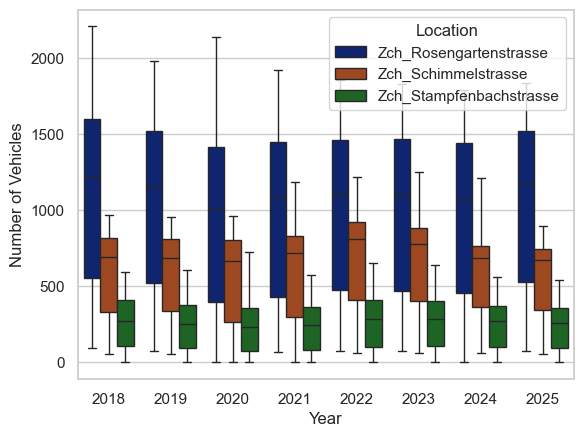

In [147]:
sns.set_theme(style="whitegrid")

# draw a boxplot by number of vehicles and location
g = sns.boxplot(
    data=df_traffic,
    x="Year", y="meanVehicles", hue="Location",
    palette="dark"
).set(
    xlabel='Year',
    ylabel='Number of Vehicles'
)

### Save Data Set

In [148]:
df_traffic.to_csv("data/traffic_h1_2018_2025.csv", index=False)

## Air Pollution Data

### Read and Tidy Data

In [149]:
path = "data/air_pollutants_h1/"

files_pollutants = os.listdir(path)

for i in range(len(files_pollutants)):
    files_pollutants[i] = os.path.join(path, files_pollutants[i])

In [150]:
df_pollutants = read_files(file_paths=files_pollutants, drop_columns=["Status", "Intervall"], date_column="Datum")

years = range(2018, 2026)

df_pollutants = df_pollutants[df_pollutants["Year"].isin(years)]

df_pollutants.head()

,Datum,Location,Parameter,Einheit,Wert,Year,Datetime
1044322,2018-01-01T00:00+0100,Zch_Heubeeribüel,NO2,µg/m3,3.94,2018,2017-12-31 23:00:00+00:00
1044323,2018-01-01T00:00+0100,Zch_Heubeeribüel,NO,µg/m3,1.20,2018,2017-12-31 23:00:00+00:00
1044324,2018-01-01T00:00+0100,Zch_Heubeeribüel,NOx,ppb,3.02,2018,2017-12-31 23:00:00+00:00
1044325,2018-01-01T00:00+0100,Zch_Heubeeribüel,O3,µg/m3,51.42,2018,2017-12-31 23:00:00+00:00
1044326,2018-01-01T00:00+0100,Zch_Rosengartenstrasse,NO2,µg/m3,17.20,2018,2017-12-31 23:00:00+00:00


In [151]:
param_units_pollutants = (
    df_pollutants[["Parameter", "Einheit"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

param_units_pollutants

,Parameter,Einheit
0,NO2,µg/m3
1,NO,µg/m3
2,NOx,ppb
3,O3,µg/m3
4,PM10,µg/m3
5,PM2.5,µg/m3
6,CO,mg/m3
7,SO2,µg/m3


### Create Pivot Table

In [152]:
# from long to wide format, so that each pollutant has its own column
df_pollutants_pivot = (
    df_pollutants
    .pivot(index=["Datetime", "Location", "Year"], columns="Parameter", values="Wert")
    .reset_index()
    .loc[:, ["Year", "Datetime", "Location", "NO2", "O3", "PM10"]]
)

# remove multiindex
df_pollutants_pivot.columns.name = None

df_pollutants_pivot.tail()

,Year,Datetime,Location,NO2,O3,PM10
280507,2025,2025-12-31 21:00:00+00:00,Zch_Stampfenbachstrasse,54.46,4.00,73.77
280508,2025,2025-12-31 22:00:00+00:00,Zch_Heubeeribüel,18.50,37.05,23.64
280509,2025,2025-12-31 22:00:00+00:00,Zch_Rosengartenstrasse,58.67,4.40,90.68
280510,2025,2025-12-31 22:00:00+00:00,Zch_Schimmelstrasse,60.34,1.94,89.89
280511,2025,2025-12-31 22:00:00+00:00,Zch_Stampfenbachstrasse,57.05,2.33,96.60


In [153]:
# TODO: check/ask why there are negative values

df_pollutants_pivot.describe()

,Year,NO2,O3,PM10
count,280512.000000,275856.000000,276367.000000,222888.000000
mean,2021.500342,24.447713,50.039260,14.420058
std,2.291143,17.346719,31.212433,9.451266
min,2018.000000,-0.070000,-0.830000,-9.850000
25%,2020.000000,10.420000,25.550000,8.140000
50%,2021.500000,20.800000,49.540000,12.510000
75%,2024.000000,34.800000,70.390000,18.360000
max,2025.000000,308.120000,196.510000,593.440000


### Check Zero Values and Number of Data Points

In [154]:
print("df_pollutants_pivot shape:", df_pollutants_pivot.shape)

print(df_pollutants_pivot.isnull().sum())

(df_pollutants_pivot
.groupby(["Year", "Location"], as_index=False)
.agg(count_Datetime=("Datetime", "count"),
     count_NO2=("NO2", "count"),
     count_O3=("O3", "count"),
     count_PM10=("PM10", "count")))

df_pollutants_pivot shape: (280512, 6)
Year            0
Datetime        0
Location        0
NO2          4656
O3           4145
PM10        57624
dtype: int64


,Year,Location,count_Datetime,count_NO2,count_O3,count_PM10
0,2018,Zch_Heubeeribüel,8760,8554,8696,0
1,2018,Zch_Rosengartenstrasse,8760,8607,8371,8663
2,2018,Zch_Schimmelstrasse,8760,8585,8568,8625
3,2018,Zch_Stampfenbachstrasse,8760,8709,8679,8663
4,2019,Zch_Heubeeribüel,8760,8632,8706,0
5,2019,Zch_Rosengartenstrasse,8760,8689,8642,8502
6,2019,Zch_Schimmelstrasse,8760,8623,8663,8712
7,2019,Zch_Stampfenbachstrasse,8760,8704,8721,8735
8,2020,Zch_Heubeeribüel,8784,8629,8612,0
9,2020,Zch_Rosengartenstrasse,8784,8717,8693,8702


It seems like measuring PM10 at Heubeeribüel started in 2024 only. Furthermore, there are no measurements for Rosengartenstrasse in 2012 and only a few in 2013.

As there are a lot of values missing for Heubeeribüel and we don't have any traffic data for this location, we decided to remove it.

In [155]:
df_pollutants_pivot = df_pollutants_pivot[df_pollutants_pivot["Location"] != "Zch_Heubeeribüel"]

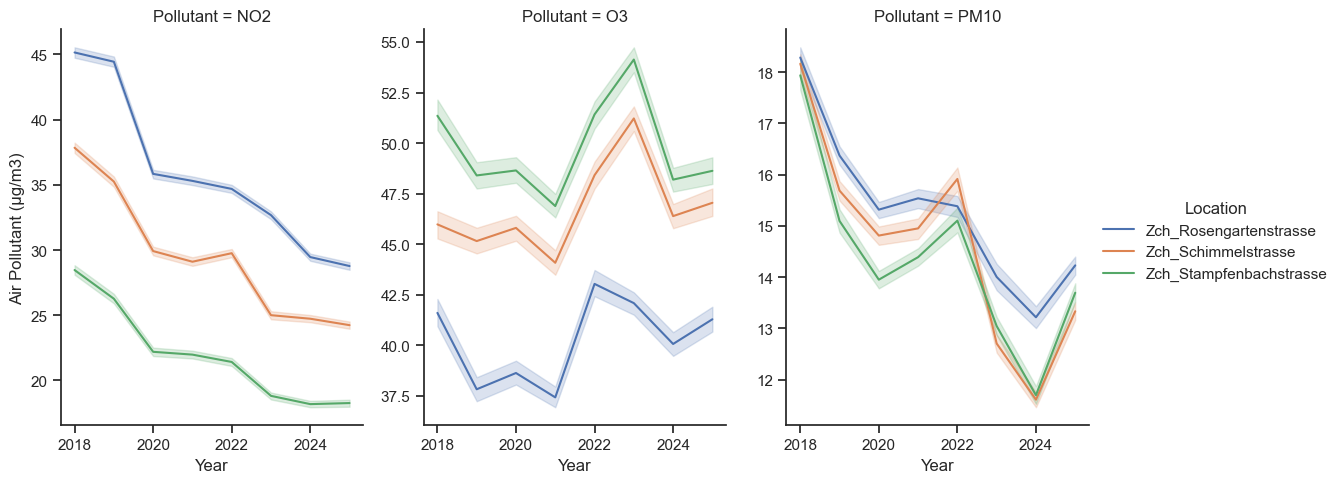

In [156]:
df_pollutants_plot = pd.melt(
    df_pollutants_pivot,
    id_vars=["Datetime", "Year", "Location"],
    value_vars=["NO2", "O3", "PM10"],
    var_name="Pollutant",
    value_name="Value"
)

sns.set_theme(style="ticks")

# Plot the lines on two facets
(sns.relplot(
    data=df_pollutants_plot,
    x="Year", y="Value",
    hue="Location", col="Pollutant",
    kind="line",
    height=5, aspect=.75, facet_kws={'sharey': False, 'sharex': True},
)
 .set_axis_labels("Year", "Air Pollutant (µg/m3)"))

### Save Data Set

In [157]:
df_pollutants_pivot.to_csv("data/pollution_h1_2018_2025.csv", index=False)

## Meteo Data

### Read and Tidy Data

In [158]:
path = "data/ugz_meteo_h1/"

files_pollutants = os.listdir(path)

for i in range(len(files_pollutants)):
    files_pollutants[i] = os.path.join(path, files_pollutants[i])

In [159]:
df_meteo = read_files(file_paths=files_pollutants, drop_columns=["Status", "Intervall"], date_column="Datum")

years = range(2018, 2026)

df_meteo = df_meteo[df_meteo["Year"].isin(years)]

df_meteo.head()

,Datum,Location,Parameter,Einheit,Wert,Year,Datetime
953802,2018-01-01T00:00+0100,Zch_Rosengartenstrasse,Hr,%Hr,67.36,2018,2017-12-31 23:00:00+00:00
953803,2018-01-01T00:00+0100,Zch_Rosengartenstrasse,RainDur,min,0.00,2018,2017-12-31 23:00:00+00:00
953804,2018-01-01T00:00+0100,Zch_Rosengartenstrasse,T,°C,9.02,2018,2017-12-31 23:00:00+00:00
953805,2018-01-01T00:00+0100,Zch_Rosengartenstrasse,WD,°,236.74,2018,2017-12-31 23:00:00+00:00
953806,2018-01-01T00:00+0100,Zch_Rosengartenstrasse,WVv,m/s,1.85,2018,2017-12-31 23:00:00+00:00


In [160]:
param_units_meteo = (
    df_meteo[["Parameter", "Einheit"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

param_units_meteo

,Parameter,Einheit
0,Hr,%Hr
1,RainDur,min
2,T,°C
3,WD,°
4,WVv,m/s
5,p,hPa
6,StrGlo,W/m2
7,WVs,m/s


### Create Pivot Table

In [161]:
df_meteo_pivot = (
    df_meteo
    .pivot(index=["Datetime", "Location", "Year"], columns="Parameter", values="Wert")
    .reset_index()
    .loc[:, ["Year", "Datetime", "Location", "Hr", "RainDur", "T", "WVv", "StrGlo"]]
)

df_meteo_pivot.columns.name = None

# remove Heubeeribüel
df_meteo_pivot = df_meteo_pivot[df_meteo_pivot["Location"] != "Zch_Heubeeribüel"]

df_meteo_pivot.tail()

,Year,Datetime,Location,Hr,RainDur,T,WVv,StrGlo
227922,2025,2025-12-31 21:00:00+00:00,Zch_Schimmelstrasse,62.25,0.0,-2.36,0.38,NaN
227923,2025,2025-12-31 21:00:00+00:00,Zch_Stampfenbachstrasse,64.58,0.0,-2.63,1.11,0.01
227925,2025,2025-12-31 22:00:00+00:00,Zch_Rosengartenstrasse,71.02,0.0,-3.68,0.05,NaN
227926,2025,2025-12-31 22:00:00+00:00,Zch_Schimmelstrasse,64.54,0.0,-2.79,0.13,NaN
227927,2025,2025-12-31 22:00:00+00:00,Zch_Stampfenbachstrasse,66.82,0.0,-3.11,0.27,0.02


The variable "StrGlo" (radiation) is measured for the location Stampfenbachstrasse only. According to the research assistant of the City of Zurich which prepares the meteo and air pollution data, it is sensible to extrapolate the data measured at one location for the other location per datetime value. Therefore, we implement that.

In [162]:
df_meteo_pivot["StrGlo"] = (
    df_meteo_pivot.groupby("Datetime")["StrGlo"]
      .transform("first")
)

In [163]:
df_meteo_pivot.describe()

,Year,Hr,RainDur,T,WVv,StrGlo
count,210384.000000,205253.000000,208049.000000,207320.000000,206864.000000,210117.000000
mean,2021.500342,69.617717,4.814212,12.460484,0.793365,142.151315
std,2.291144,17.762133,13.969101,7.937261,0.914969,230.227800
min,2018.000000,12.700000,0.000000,-10.990000,0.000000,0.010000
25%,2020.000000,57.350000,0.000000,6.210000,0.200000,0.020000
50%,2021.500000,73.000000,0.000000,11.950000,0.440000,4.430000
75%,2024.000000,83.910000,0.000000,18.410000,1.050000,199.300000
max,2025.000000,101.370000,137.800000,36.380000,10.560000,1041.180000


### Check Zero Values and Number of Data Points

In [164]:
print("df_meteo_pivot shape:", df_pollutants_pivot.shape)

print(df_meteo_pivot.isnull().sum())

df_meteo_pivot shape: (210384, 6)
Year           0
Datetime       0
Location       0
Hr          5131
RainDur     2335
T           3064
WVv         3520
StrGlo       267
dtype: int64


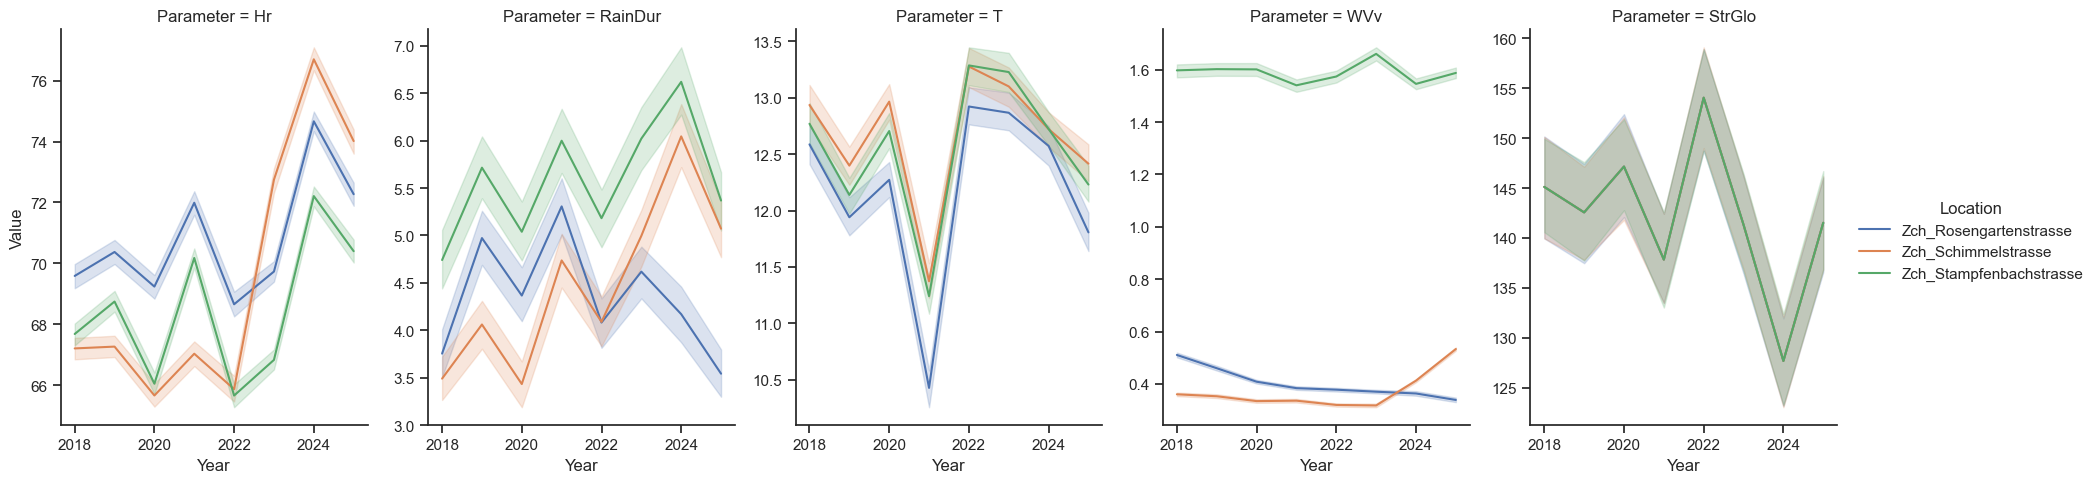

In [165]:
df_meteo_plot = pd.melt(
    df_meteo_pivot,
    id_vars=["Datetime", "Year", "Location"],
    value_vars=["Hr", "RainDur", "T", "WVv", "StrGlo"],
    var_name="Parameter",
    value_name="Value"
)

sns.set_theme(style="ticks")

# Plot the lines on two facets
sns.relplot(
    data=df_meteo_plot,
    x="Year", y="Value",
    hue="Location", col="Parameter",
    kind="line",
    height=5, aspect=.75, facet_kws={'sharey': False, 'sharex': True},
).set_axis_labels("Year", "Value")

### Save Data Set

In [166]:
df_meteo_pivot.to_csv("data/meteo_h1_2018_2025.csv", index=False)

## Merge Data Sets

Because there are a lot of values missing in the traffic data set, we will use the years from 2018 to 2025 only.

In [167]:
# Combine all datasets across days and locations
df_combined = df_pollutants_pivot.merge(df_meteo_pivot, on=["Datetime", "Location"], how="outer") \
    .merge(df_traffic, on=["Datetime", "Location"], how="outer")

# remove the duplicated column "Year"
df_combined = df_combined.drop(columns=["Year_x", "Year_y"])

df_combined.tail()

,Datetime,Location,NO2,O3,PM10,Hr,RainDur,T,WVv,StrGlo,Year,Date,Time,Month,Weekday,YearMonth,meanVehicles
210379,2025-12-31 21:00:00+00:00,Zch_Schimmelstrasse,61.53,2.29,75.61,62.25,0.0,-2.36,0.38,0.01,2025.0,2025-12-31,21:00:00,Dec,Wed,2025-12-01,472.5
210380,2025-12-31 21:00:00+00:00,Zch_Stampfenbachstrasse,54.46,4.00,73.77,64.58,0.0,-2.63,1.11,0.01,2025.0,2025-12-31,21:00:00,Dec,Wed,2025-12-01,242.0
210381,2025-12-31 22:00:00+00:00,Zch_Rosengartenstrasse,58.67,4.40,90.68,71.02,0.0,-3.68,0.05,0.02,2025.0,2025-12-31,22:00:00,Dec,Wed,2025-12-01,791.5
210382,2025-12-31 22:00:00+00:00,Zch_Schimmelstrasse,60.34,1.94,89.89,64.54,0.0,-2.79,0.13,0.02,2025.0,2025-12-31,22:00:00,Dec,Wed,2025-12-01,518.0
210383,2025-12-31 22:00:00+00:00,Zch_Stampfenbachstrasse,57.05,2.33,96.60,66.82,0.0,-3.11,0.27,0.02,2025.0,2025-12-31,22:00:00,Dec,Wed,2025-12-01,353.0


In [168]:
print(df_combined.isnull().sum())

Datetime           0
Location           0
NO2             3479
O3              3416
PM10            5010
Hr              5131
RainDur         2335
T               3064
WVv             3520
StrGlo           267
Year             900
Date             900
Time             900
Month            900
Weekday          900
YearMonth        900
meanVehicles     900
dtype: int64


<Axes: >

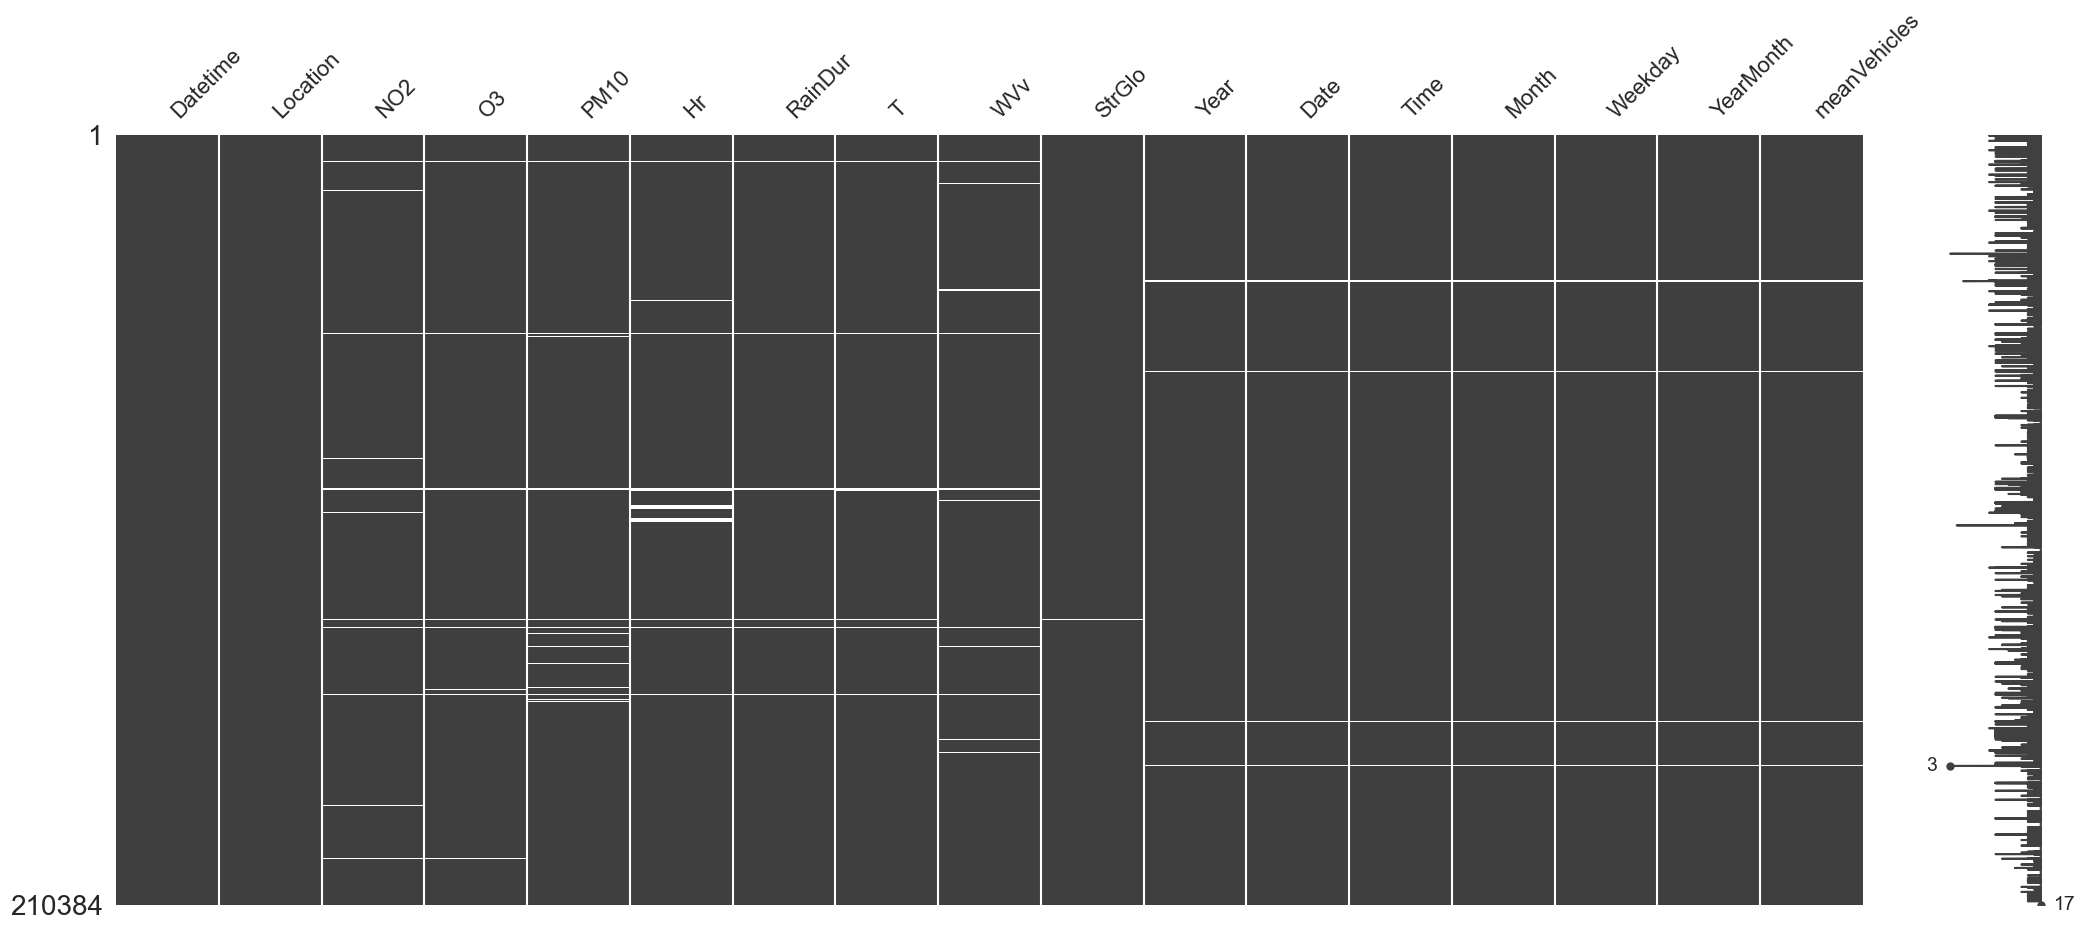

In [169]:
# TODO discuss which features to keep.

msno.matrix(df_combined)

According to the NaN-matrix I would suggest it so be safe to simply exclude the NaNs.

In [170]:
df_combined_excl_nan = df_combined.dropna()

print("df_combined incl nan:", df_combined.shape)
print("df_combined excl nan:", df_combined_excl_nan.shape)

df_combined incl nan: (210384, 17)
df_combined excl nan: (197251, 17)


### Save Data Set

In [171]:
df_combined.to_csv("data/combined_h1_2018_2025_incl_nan.csv", index=False)
df_combined_excl_nan.to_csv("data/combined_h1_2018_2025_excl_nan.csv", index=False)